# Random Forest

## Motivation
#### Random Forest is an ensemble machine learning algorithm that combines multiple decision trees to capture complex, non-linear relationships and interactions among features. Unlike logistic regression and linear SVM, it does not assume a linear relationship between the predictors and treatment response, making it useful for exploring whether molecular and clinical features contain more complex predictive patterns. In this analysis, Random Forest was evaluated as a complementary non-linear approach while also enabling assessment of feature importance.

In [1]:
## Loading required libraries

import pandas as pd
import numpy as np
from sklearn.base import clone
import matplotlib.pyplot as plt
from src.utils.plots import plot_histograms, plot_response_barplots, plot_response_boxplots, plot_cv_metrics, corr_heatmap, missin_val_heatmap, select_threshold_from_cv, plot_external_validation_curves, plot_rf_heatmap
from src.utils.plots import stacked_bar_chart, plot_hyperparam_search, violin_plot_predictions, forest_plot_coefficients, plot_bootstrap_ci_forest, plot_feature_significance
from src.utils.data_formatting import standarize_sex_colum, extract_patient_info, match_patients, align_column_names
import warnings
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from typing import Literal
from typing import Literal
from scipy import stats
import argparse
from src.utils.config import load_config
from src.utils.helper_func import calculate_binary_metrics, stratified_bootstrap_external_metrics, bootstrap_external_metrics, feature_significance
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import  roc_auc_score, confusion_matrix, average_precision_score, f1_score, recall_score, precision_score,  ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier


In [2]:
# Loading parameters from configuration file
args = {"config":"configs/Params_set.yml"}

cfg = load_config(args["config"])


## Part A. Training Cohort Overview 

In [3]:
# Loading training and validation cohort
training_cohort = pd.read_excel(cfg["Features"]["Final_Checkmate"], sheet_name="Features")
validation_cohort = pd.read_excel(cfg["Features"]["Final_Emtab"], sheet_name="Features")

In [4]:
train_class_labels = training_cohort["Response"].value_counts()
val_class_labels = validation_cohort["Response"].value_counts()
class_labels = pd.concat([train_class_labels, val_class_labels], axis = 1)

### A1. The following plot shows the distribution of class labels in the training and external validation cohorts.

(<Figure size 480x360 with 1 Axes>,
 <Axes: title={'center': 'Number of patients in each class label'}>)

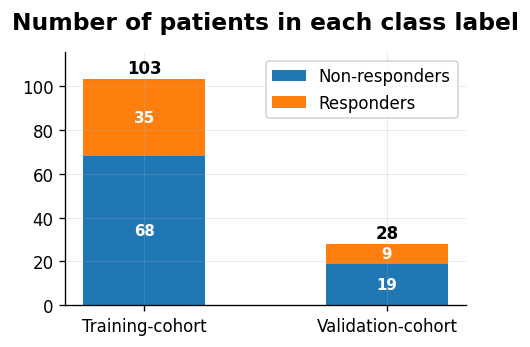

In [5]:
stacked_bar_chart(["Training-cohort", "Validation-cohort"],categories=["Non-responders", "Responders"], 
                  values = [class_labels.iloc[0,:], class_labels.iloc[1,:]], title = "Number of patients in each class label",  figsize = [4,3])

In [6]:
training_cohort.head()

,Received_Prior_Therapy,TMB_Counts,BAP1,PBRM1,SETD2,VHL,Response,T_effector,Angiogenesis,FAO/AMPK,Cell_Cycle,FAS/Pentose_Phosphate,Stroma,Myeloid_Inflammation,Complement_Cascade,Omega_oxidation,Tumor_inflammation_score,Cohort
0,Yes,105.0,WT,MUT,WT,WT,Non-Responders,0.148237,0.207268,0.426179,-0.718344,-0.802468,-0.972039,-1.191040,-0.094806,0.388907,-0.236995,CM-025
1,Yes,28.0,WT,WT,WT,WT,Responders,1.174420,-0.074041,-1.016133,0.081855,-0.003479,1.047075,0.809109,0.484398,-0.572133,1.030557,CM-025
2,Yes,181.0,WT,MUT,WT,WT,Responders,-0.260588,0.973303,1.286888,-0.856730,-0.832729,-0.669412,-1.164171,-1.296157,-0.321287,-0.652298,CM-025
3,Yes,NaN,NaN,NaN,NaN,NaN,Non-Responders,0.035187,-0.310847,0.106104,0.490507,1.029595,1.261651,0.551131,0.209985,-0.929884,0.443611,CM-025
4,Yes,NaN,NaN,NaN,NaN,NaN,Responders,1.560963,-0.515835,-0.646998,0.809698,-0.208788,0.236488,0.165933,1.066020,0.568143,0.553803,CM-025


### A2. Missing Data Distribution Training Cohort

##### The following heatmap illustrates the pattern of missing values across all features in the training cohort. Missing values are primarily observed in the TMB_Counts, BAP1, PBRM1, SETD2, VHL features. The missing values will be imputed using the median strategy within the preprocessing pipeline, with imputation parameters learned from the training data to prevent information leakage. 

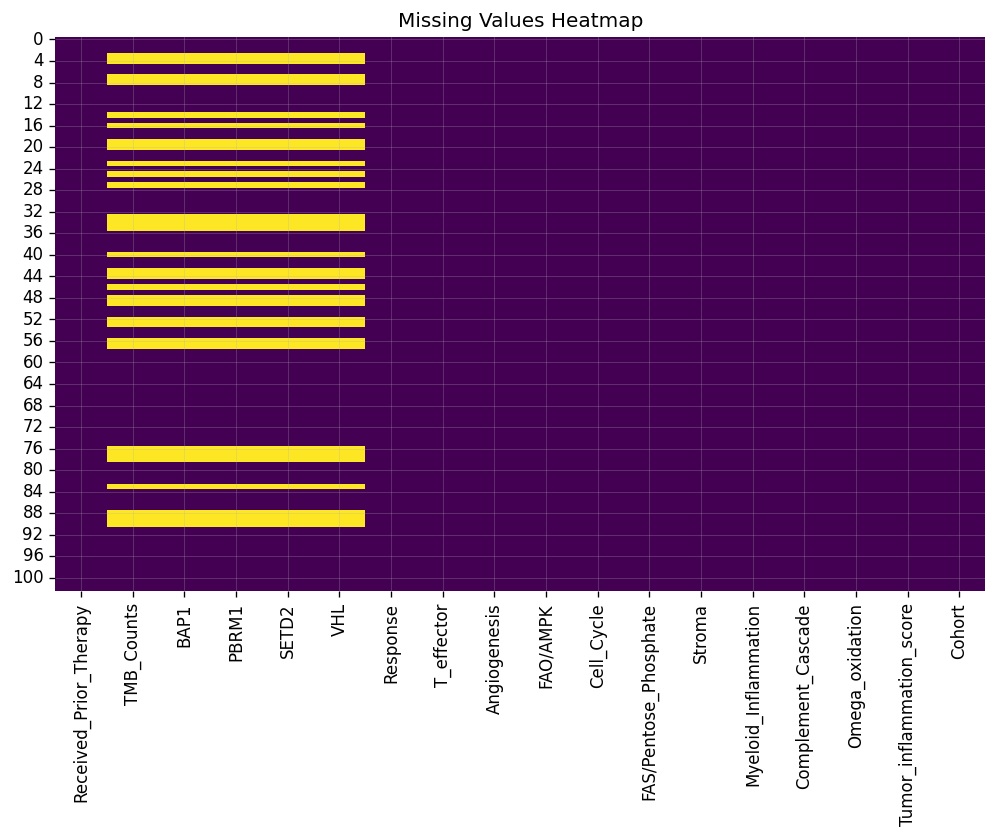

In [7]:
missin_val_heatmap(training_cohort)

## Part B. Feature engineering

### B1. Binary Encoding of Categorical Features

In [8]:

training_cohort["VHL"] = training_cohort["VHL"].map({
    "WT": 0,
    "MUT": 1
})

training_cohort["BAP1"] = training_cohort["BAP1"].map({
    "WT": 0,
    "MUT": 1
})

training_cohort["PBRM1"] = training_cohort["PBRM1"].map({
    "WT": 0,
    "MUT": 1
})

training_cohort["SETD2"] = training_cohort["SETD2"].map({
    "WT": 0,
    "MUT": 1
})

### B2. Since VHL is the originator or founding mutation of ccRCC and observed in 60% to 70% most of patients, hence we wont consider in our feature list. 

In [9]:
## More than half of the patients have missing TM_CD8 and TC_CD8, we will remove it from our feature list. 
training_cohort.drop(columns=[ "VHL", "Received_Prior_Therapy","Cohort"], inplace=True)

In [10]:
corr_mat = training_cohort.drop("Response", axis = 1).corr()

### B3. Pairwise Correlation of Training Cohort Features

##### The following correlation heatmap illustrates the pairwise relationships among the molecular and clinical features in the training cohort. Most feature pairs exhibit weak to moderate correlations, indicating limited multicollinearity. However, the T_effector signature and Tumor Inflammation Score show a strong positive correlation (r = 0.84), suggesting that they capture similar biological information. To reduce multicollinearity and avoid redundancy in the feature set, Tumor Inflammation Score will be excluded from subsequent analyses, while T_effector is retained due to its well-established association with immunotherapy response.

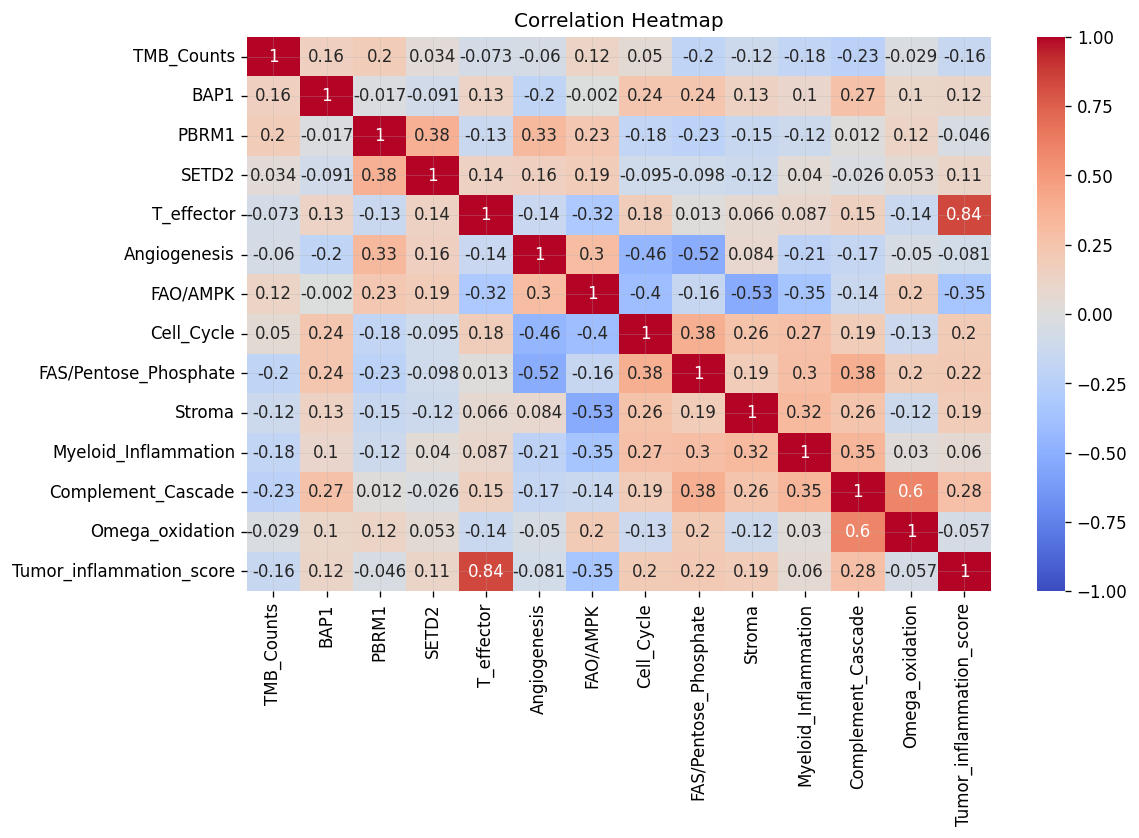

In [11]:
corr_heatmap(corr_mat)

In [12]:
# T_effector and Tumor_inflammation_score are highly correlated. To reduce the multicollinearity, Tumar_inflammation_score was excluded from the feature set.

training_cohort.drop(columns=["Tumor_inflammation_score"], inplace=True)

### B4. Splitting training cohort into training features and the target variable.

In [13]:
# Splitting the data into features and the target variable

X = training_cohort.drop(columns="Response")
y = training_cohort["Response"]

### B5. Encoding target variable into binary variable.

In [14]:
# Encoding target variable into binary variable.

y = y.replace({
    "Non-Responders": 0,
    "Responders": 1
})

## Part C. Hyperparameter Tuning
##### Hyperparameter tuning was performed to identify the optimal combination of model parameters that maximizes predictive performance. The search was conducted using repeated stratified cross-validation to improve model generalization while reducing the risk of overfitting.

### C1. Modeling Pipeline Creation

In [15]:
# Dividing model features into numeric and binary types.

num_fetres = ["T_effector", "Angiogenesis", "FAO/AMPK", "Cell_Cycle", "TMB_Counts", "FAS/Pentose_Phosphate", "Stroma", "Myeloid_Inflammation",
               "Complement_Cascade", "Omega_oxidation"]
binary_fetres = ["PBRM1","BAP1", "SETD2"]

In [16]:
## Creating pipeline to perform preprocessing of data

binary_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])
numeric_pipeline  = Pipeline([("imputer", SimpleImputer(strategy="median"))])
#cat_pipline = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),("encoder", OneHotEncoder(handle_unknown="ignore", drop = "if_binary"))])
preprocessor = ColumnTransformer([("binary", binary_pipeline, binary_fetres), ("num", numeric_pipeline, num_fetres)]) #, ("cat", cat_pipline, cat_fetres)

pipeline = Pipeline([("preprocessor", preprocessor), ("model", RandomForestClassifier(n_estimators=100,  random_state=42))])



### C2. Hyperparameter Search Space

In [17]:
param_grid = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [3, 5, 7,10],
    "model__min_samples_split": [2, 5, 7, 10],
    "model__min_samples_leaf": [ 2, 4, 6, 8],
    "model__max_features": ["sqrt", 0.5],
    "model__class_weight": [ "balanced"]
}

### C3. Grid Search

##### Standard 5-fold CV was used for RF hyperparameter tuning due to the increased computational cost of ensemble methods, LR and SVM used repeated stratified CV for more stable parameter estimates.

In [18]:
grid = GridSearchCV(estimator =pipeline,
              param_grid=param_grid, 
              cv=5, 
              scoring= { 'f1': 'f1', "sensitivity":"recall", "auprc":"average_precision", "auroc":"roc_auc"},
              n_jobs=-1,
              refit="auprc")
grid.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': ['balanced'], 'model__max_depth': [3, 5, ...], 'model__max_features': ['sqrt', 0.5], 'model__min_samples_leaf': [2, 4, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'auprc': 'average_precision', 'auroc': 'roc_auc', 'f1': 'f1', 'sensitivity': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'auprc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose ver

### C4. Best Hyperparameters

In [19]:
grid.best_params_

{'model__class_weight': 'balanced',
 'model__max_depth': 3,
 'model__max_features': 'sqrt',
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 2,
 'model__n_estimators': 500}

### C5. Best AUPRC score

In [20]:
grid.best_score_

np.float64(0.42679011464725747)

In [21]:
param_res = pd.DataFrame(grid.cv_results_)

### C6. Random Forest Hyperparameter Search

##### The following figure summarizes the Random Forest hyperparameter search using cross-validated AUPRC. Different combinations of the number of estimators, maximum tree depth, number of features considered at each split, and minimum samples per leaf were evaluated. The best performance (AUPRC = 0.426) was obtained with n_estimators = 500, max_features = sqrt, max_depth = 3, and min_samples_leaf = 2, as highlighted by the gold border. Overall, the relatively similar AUPRC values across several configurations suggest limited sensitivity to changes in the Random Forest hyperparameters.

(<Figure size 1200x960 with 5 Axes>,
 array([[<Axes: title={'center': 'max_features = 0.5'}, ylabel='n_estimators = 200\n\nmax_depth'>,
         <Axes: title={'center': 'max_features = sqrt'}>],
        [<Axes: xlabel='min_samples_leaf', ylabel='n_estimators = 500\n\nmax_depth'>,
         <Axes: xlabel='min_samples_leaf'>]], dtype=object))

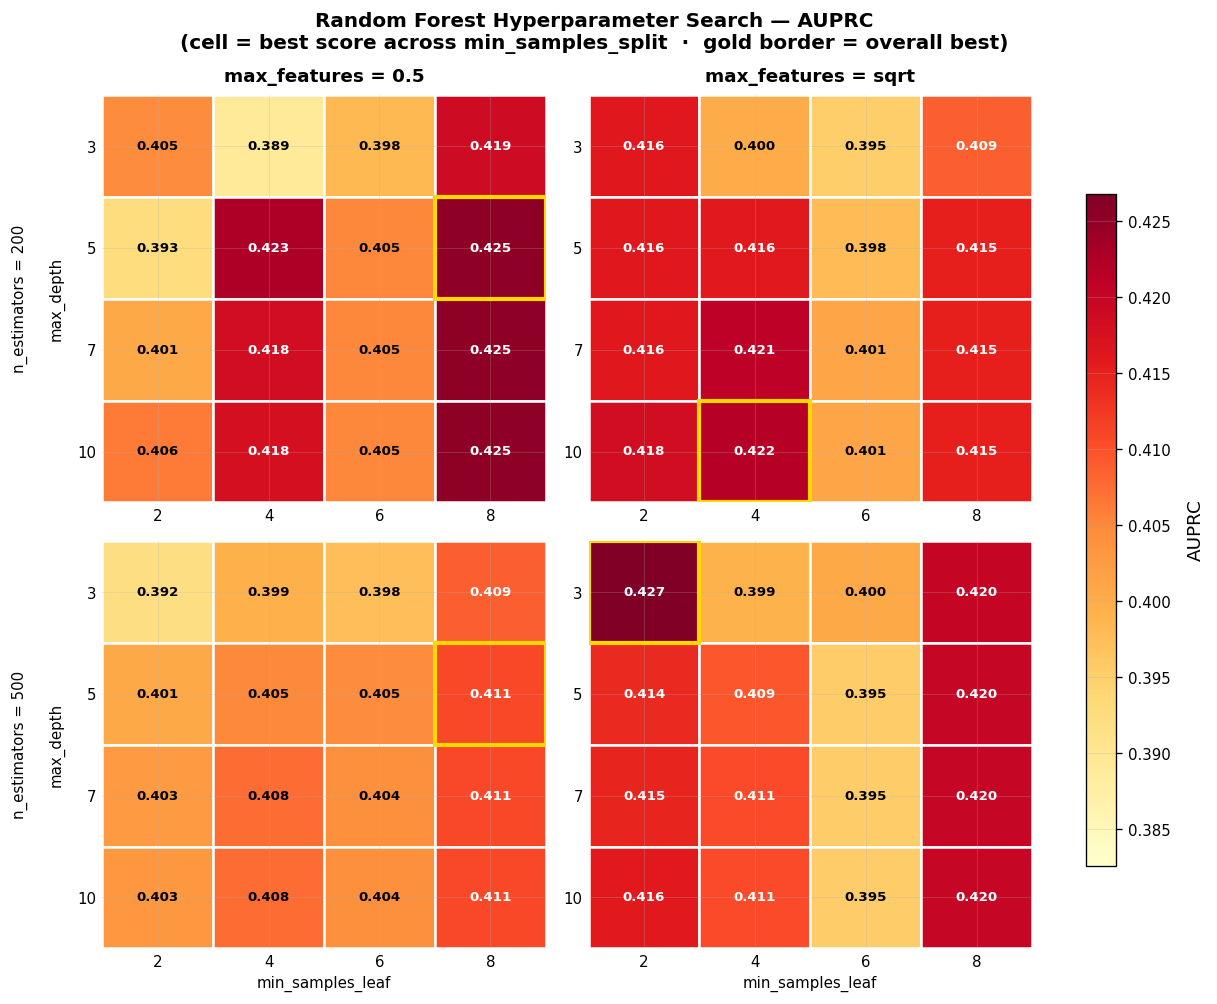

In [22]:
plot_rf_heatmap(param_res,  metric = "auprc" )

In [23]:
best_rf_model  = grid.best_estimator_

## Part D. Model Training and Cross-Validation
##### Given the relatively small and imbalanced dataset, repeated stratified cross-validation was used to obtain a reliable estimate of model performance. This approach ensures that each sample contributes to both training and evaluation while preserving the class distribution across folds.

In [24]:

cv = RepeatedStratifiedKFold(n_splits=5 , n_repeats=10 , random_state=42)

result = []
all_coefficients = []
fold_prob = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]

    fold_pipeline = clone(best_rf_model)

    fold_pipeline.fit(X_train, y_train)

    y_prob = fold_pipeline.predict_proba(X_test)[:, 1]
    y_pred = fold_pipeline.predict(X_test)


    feature_names = (
        fold_pipeline.named_steps["preprocessor"]
        .get_feature_names_out()
    )


    auroc = roc_auc_score(y_test, y_prob)

    sensitivity = recall_score(y_test, y_pred)

    avg_precision = average_precision_score(y_test, y_prob)

    f1score = f1_score(y_test, y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)

    rf_model = fold_pipeline.named_steps["model"]

    result.append({"fold": fold, "AUROC":auroc, "AUPRC": 
                   avg_precision,"Sensitivity": sensitivity,
                     "Specificity": specificity , "F1_score":f1score})
    

    fold_prob.append({"fold_num": fold,
                      "indices": test_idx,
                      "y_true": y_test, 
                      "y_prob": y_prob,
                      "predicted_label": y_pred})

    fold_imp = pd.DataFrame({
        "Fold": fold,
        "Feature": feature_names,
        "Coefficient": rf_model.feature_importances_
    })
    all_coefficients.append(fold_imp)
    

    coef_df = pd.concat(all_coefficients, ignore_index=True)


fold_pred = pd.DataFrame(fold_prob)
result_df = pd.DataFrame(result)
result_df.describe()

,fold,AUROC,AUPRC,Sensitivity,Specificity,F1_score
count,50.00000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,25.50000,0.464615,0.425632,0.180000,0.803187,0.219659
std,14.57738,0.105486,0.091479,0.125174,0.108364,0.139029
min,1.00000,0.219780,0.260844,0.000000,0.538462,0.000000
25%,13.25000,0.385400,0.362589,0.142857,0.728022,0.166667
50%,25.50000,0.479592,0.417856,0.142857,0.785714,0.190909
75%,37.75000,0.543956,0.495527,0.285714,0.857143,0.333333
max,50.00000,0.724490,0.609042,0.571429,1.000000,0.533333


In [25]:
summary = result_df[["AUROC", "AUPRC", "Sensitivity", "Specificity", "F1_score"]].agg(
    ["mean", "std"]
)

In [26]:
# Saving fold results

fold_pred.to_csv(
    "results/model_eval/rf_cross_val_predictions.csv",
    index=False,
)


result_df.to_csv(
    "results/model_eval/rf_cross_val_metrics.csv",
    index=False,
)

coef_df.to_csv(
    "results/model_eval/rf_cross_val_coef.csv",
    index=False,
)

In [27]:
mean_coef_df = (
    coef_df
    .groupby("Feature")["Coefficient"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

### D2. Cross-Validation Feature Importance

##### The following figure shows the mean Random Forest feature importance across cross-validation folds, with error bars representing variability across folds. Cell Cycle, FAO/AMPK and myeloid inflammation show the highest overall importance, followed by Stroma and Complement_Cascade, indicating greater contribution to the model's classification decisions. In contrast BAP1, SETD2 and PBRM1 show relatively lower importance. Overall, feature importance is distributed across multiple predictors, suggesting that the Random Forest does not rely predominantly on a single feature.

(<Figure size 1080x655.2 with 1 Axes>,
 <Axes: title={'center': 'Random Forest Feature Importance'}, xlabel='Mean Feature Importance'>)

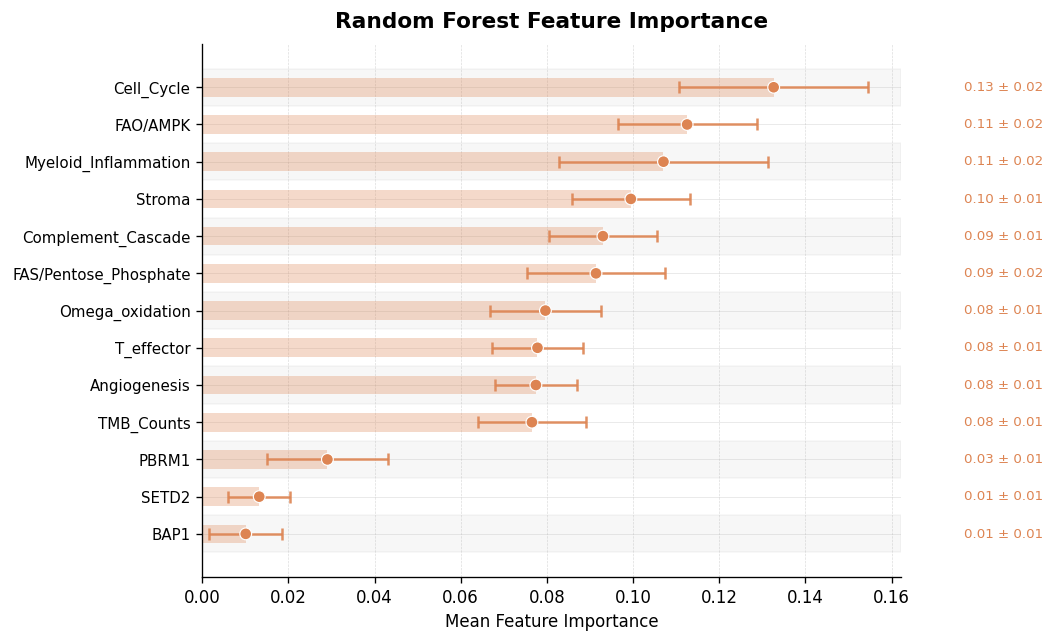

In [28]:
forest_plot_coefficients(mean_coef_df["Feature"], mean_coef_df["Coefficient"], cv_df = coef_df, col_fold = "Fold",
                         col_feature = "Feature" , col_coef = "Coefficient", title = "Random Forest Feature Importance", 
                         mode = "coefficient" , xlabel = "Mean Feature Importance")

### D3. Cross Validation Performance

##### The following figure presents the distribution of Random Forest performance metrics across repeated 5-fold cross-validation. Overall discriminative performance is modest, with substantial variability in AUROC and AUPRC across folds. The model shows notably low sensitivity, with many folds failing to correctly identify responders, while specificity remains considerably higher across most folds. Consequently, the F1 score is also relatively low and variable. These results indicate that, during cross-validation, the Random Forest model has difficulty identifying the responder class and demonstrates a strong tendency toward correctly classifying non-responders.

In [29]:
print(summary)

         AUROC     AUPRC  Sensitivity  Specificity  F1_score
mean  0.464615  0.425632     0.180000     0.803187  0.219659
std   0.105486  0.091479     0.125174     0.108364  0.139029


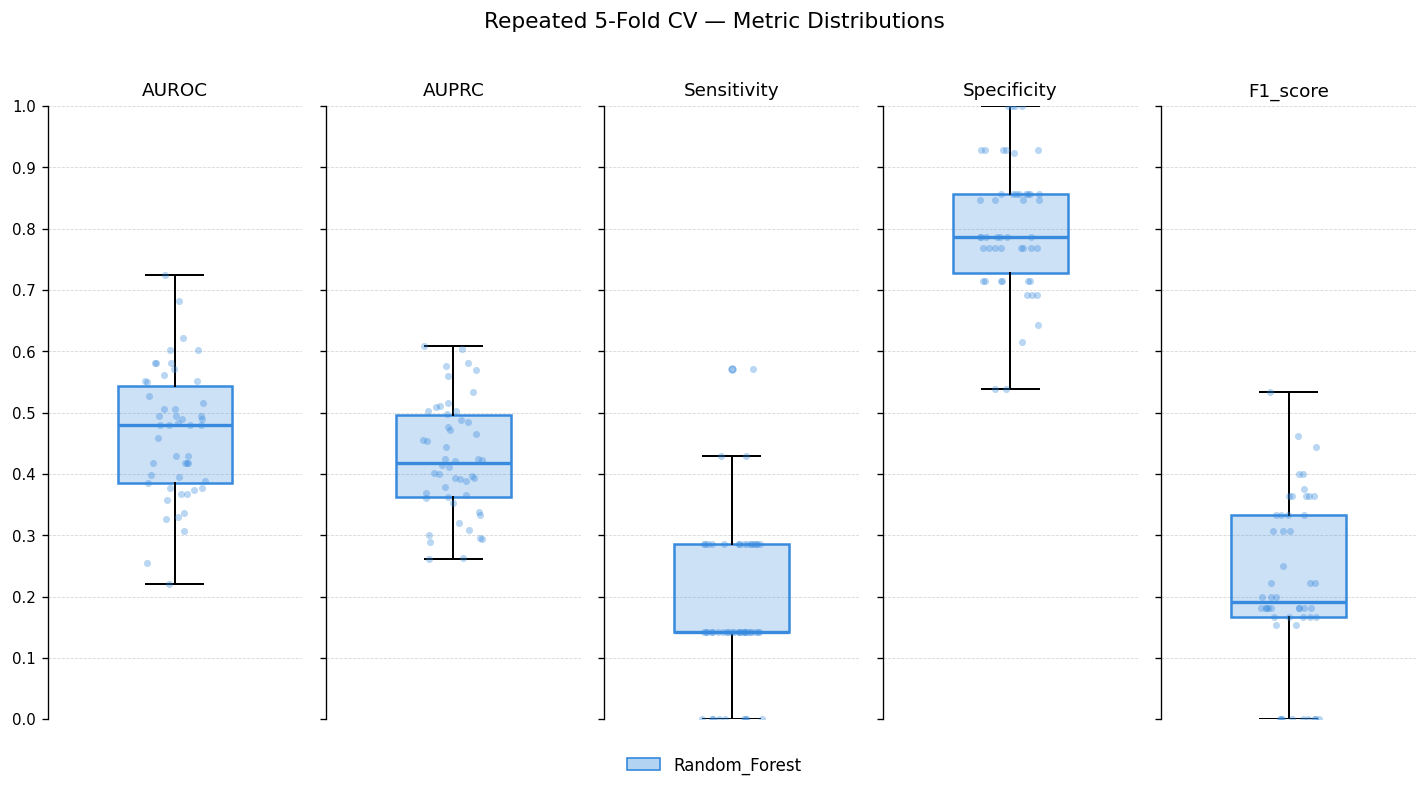

In [30]:
fig = plot_cv_metrics([result_df], ["Random_Forest"] , ["AUROC", "AUPRC", "Sensitivity", "Specificity", "F1_score"])

### D4. Optimal Decision-Score Threshold Selection

##### Motivation: Because the training dataset is relatively small and class-imbalanced, the default decision threshold may not provide the best balance between correctly identifying responders and non-responders. An optimal threshold was therefore determined from the cross-validation predictions using Youden's Index, providing a more balanced classification rule for subsequent external validation.

##### The following figure showcase the selection of the optimal decision-score threshold from repeated 5-fold cross validation. The Left panel shows the ROC curve generated from the patient averaged out-of-fold(OOF) decision scores obtained from cross validation. The right panel shows the Youden's s (TPR-FPR) at different decision-score thresholds. The threshold corresponding to the maximum Youden's J statistic (0.518) was selected as the optimal decision threshold and subsequently applied to the external validation cohort.

Patients: 103  |  Folds: 50  |  Avg repeats per patient: 10
Frozen threshold (youden): 0.5177  |  AUC: 0.4458


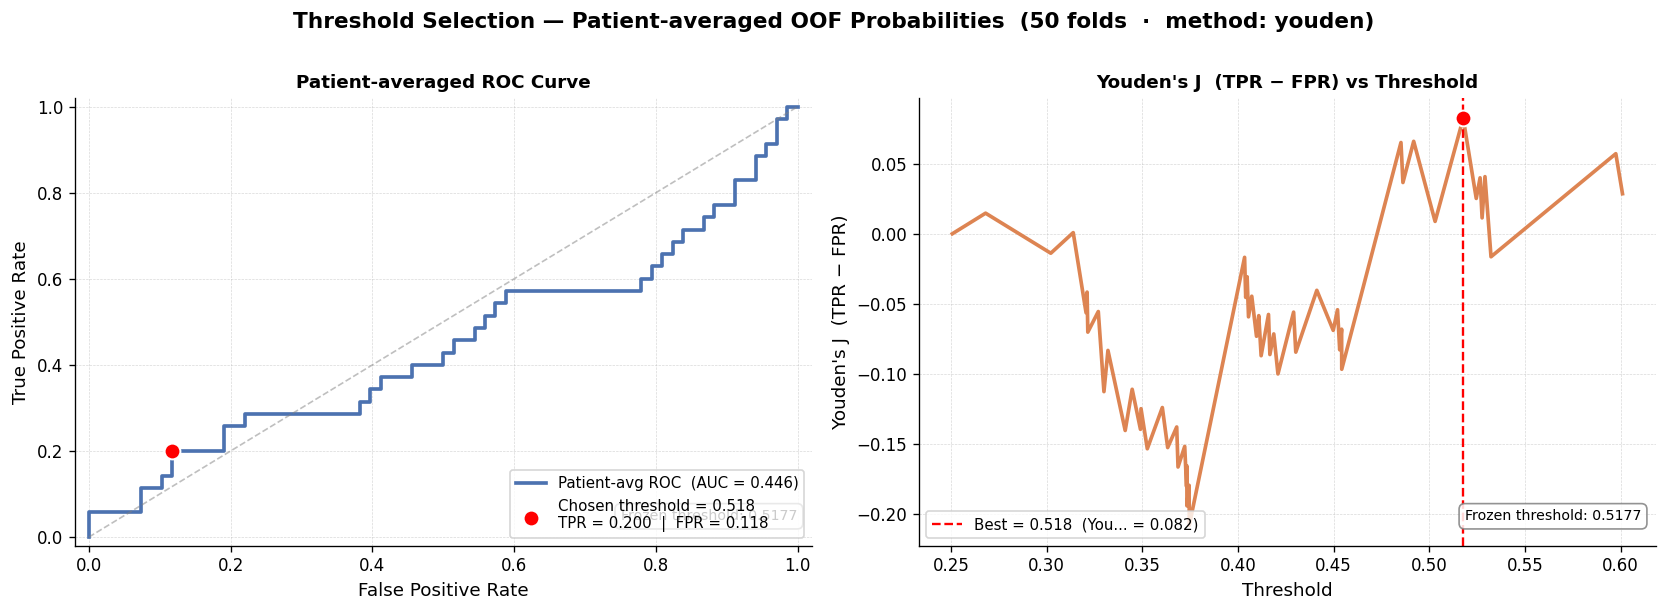

In [31]:
threshold_sel = select_threshold_from_cv(fold_prob)

### D5. Training linear svm on entire training dataset before testing on validation cohort.

In [32]:
best_rf_model.fit(X,y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('binary', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers

## Part E. Performance Evaluation on the External Validation Cohort

### E1. Validation Cohort Overview

#### Gene signatures in validation cohort are derived from Microarray data of gene expression whereas the gene signatures of training cohort derived from RNA-Seq. We first converted the gene expression into z-scores individually and then computed the gene signatures to make the feature platform independent. 

In [33]:
# Aligning validation cohort column names with training cohort column names.
feature_cols = X.columns.tolist()

validation_features = validation_cohort[feature_cols]



### E2. Missing Data Distribution Validation Cohort

##### The following heatmap illustrates the pattern of missing values across all features in the external validation cohort. Missing values are observed only in the mutation features (PBRM1, BAP1, and SETD2) and TMB_Counts, while all remaining molecular and clinical features are complete. Missing categorical features will be imputed using the most_frequent strategy, whereas the numeric TMB_Counts feature was imputed using the median. The imputation parameters were learned from the training data and then applied to the external validation cohort, ensuring consistent preprocessing while preventing information leakage

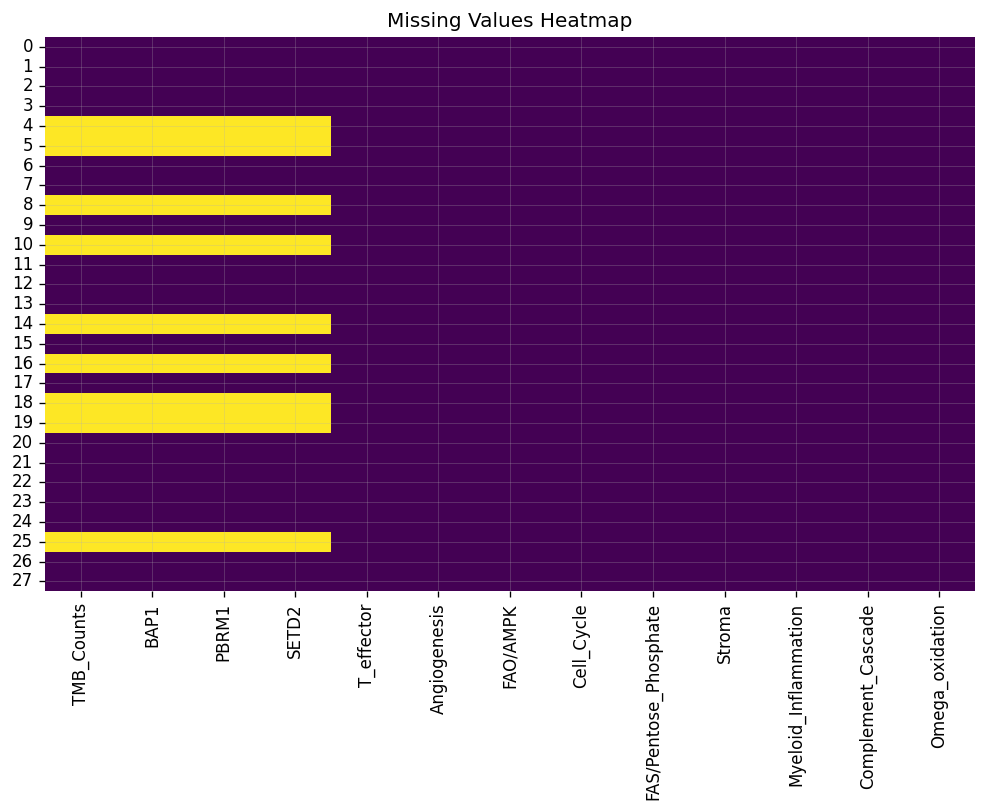

In [34]:
missin_val_heatmap(validation_features)

### E3. Binary Encoding of Categorical Features

In [35]:

validation_features.loc[~validation_features["PBRM1"].isin(["WT", np.nan]), "PBRM1"] = 1
validation_features.loc[validation_features["PBRM1"].isin(["WT"]), "PBRM1"] = 0

validation_features.loc[~validation_features["SETD2"].isin(["WT", np.nan]), "SETD2"] = 1
validation_features.loc[validation_features["SETD2"].isin(["WT"]), "SETD2"] = 0

validation_features.loc[~validation_features["BAP1"].isin(["WT", np.nan]), "BAP1"] = 1
validation_features.loc[validation_features["BAP1"].isin(["WT"]), "BAP1"] = 0

validation_features.head(5)

,TMB_Counts,BAP1,PBRM1,SETD2,T_effector,Angiogenesis,FAO/AMPK,Cell_Cycle,FAS/Pentose_Phosphate,Stroma,Myeloid_Inflammation,Complement_Cascade,Omega_oxidation
0,56.0,0,1,0,-1.249629,-1.213285,0.601988,0.093063,1.079233,-0.277245,0.162433,0.091752,0.017431
1,72.0,0,0,0,-0.575128,1.039385,0.443900,-0.820964,-0.471185,0.603002,-0.547749,-0.615865,-0.642438
2,21.0,0,0,0,0.294987,-0.325934,-0.015568,-1.462302,0.096124,0.470951,-0.696113,0.040591,-0.028226
3,34.0,0,0,0,0.196749,-0.213276,1.201464,-0.605462,0.060638,-1.477577,-0.007022,0.858854,0.797571
4,NaN,NaN,NaN,NaN,-0.637247,-0.074359,-0.644113,-0.106279,-0.460072,0.501169,0.737388,0.209353,0.074781


### E4. Separating dependent and target variables

In [36]:

X_val = validation_features
y_val = validation_cohort["Response"]

# Encoding target variable into binary variable.
y_val = y_val.replace({
    "Non-Responders": 0,
    "Responders": 1
})

##### External validation cohort contains 9 Responders and 19 Non-responders.

In [37]:
y_val.value_counts()

Response
0    19
1     9
Name: count, dtype: int64

### F1. Employing our final random forest model on external dataset. We are using decision scores for AUROC and AUPRC and obtained optimal threshold for computing specificity and sensitivity. 

In [38]:

y_prob = best_rf_model.predict_proba(X_val)[:,1]

y_pred = best_rf_model.predict(X_val)

y_val_pred = (y_prob >= threshold_sel["threshold"]).astype(int)

coefficients = best_rf_model.named_steps["model"].feature_importances_

feature_names = best_rf_model.named_steps["preprocessor"].get_feature_names_out()

auroc = roc_auc_score(y_val, y_prob)

sensitivity = recall_score(y_val, y_val_pred)

avg_precision = average_precision_score(y_val, y_prob)

f1score = f1_score(y_val, y_val_pred)

tn, fp, fn, tp = confusion_matrix(y_val, y_val_pred).ravel()
specificity = tn / (tn + fp)

print("Auroc:", auroc)
print("Auprc:", avg_precision)
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)
print("F1 Score:", f1score)


Auroc: 0.33918128654970764
Auprc: 0.2956011824432877
Sensitivity: 0.1111111111111111
Specificity: 0.8947368421052632
F1 Score: 0.16666666666666666


In [39]:
prediction_results = pd.DataFrame({
    "patient_id": X_val.index,
    "true_label": y_val.to_numpy(),
    "predicted_score": y_prob,
    "predicted_label_optimized": y_pred,
})

prediction_results.to_csv(
    "results/model_eval/rf_external_predictions.csv",
    index=False,
)


metrics = pd.DataFrame({
    "model": ["Random Forest"],
    "dataset": ["External validation"],
    "AUROC": [auroc],
    "AUPRC": [avg_precision],
    "sensitivity": [sensitivity],
    "specificity": [specificity],
    "F1": [f1score],
    "threshold": [threshold_sel["threshold"]],
})

metrics.to_csv(
    "results/model_eval/rf_external_metrics.csv",
    index=False,
)

### F2. ROC and PR Curve 

#### The following figure presents the Receiver Operating Characteristic (ROC) and Precision–Recall (PR) curves for the random forest model on the external validation cohort. The model achieved an AUROC of 0.339 and the AUPRC of 0.296 which is far below the random chance. Using the optimal probability threshold selected during cross-validation, the model achieved a sensitivity of 11%, correctly identifying only 1 out of 9 responders, and a specificity of 89.5%, correctly identifying 17 of 19 non-responders. The F1 score of 0.16 reflects the model's more limited performance in identifying responders. Overall, the substantially higher specificity than sensitivity indicates that the random forest model performs better at identifying non-responders than responders in the external validation cohort.

(<Figure size 1560x720 with 2 Axes>,
 (<Axes: title={'center': 'ROC Curve'}, xlabel='False Positive Rate  (1 − Specificity)', ylabel='True Positive Rate  (Sensitivity)'>,
  <Axes: title={'center': 'Precision-Recall Curve'}, xlabel='Recall  (Sensitivity)', ylabel='Precision  (PPV)'>))

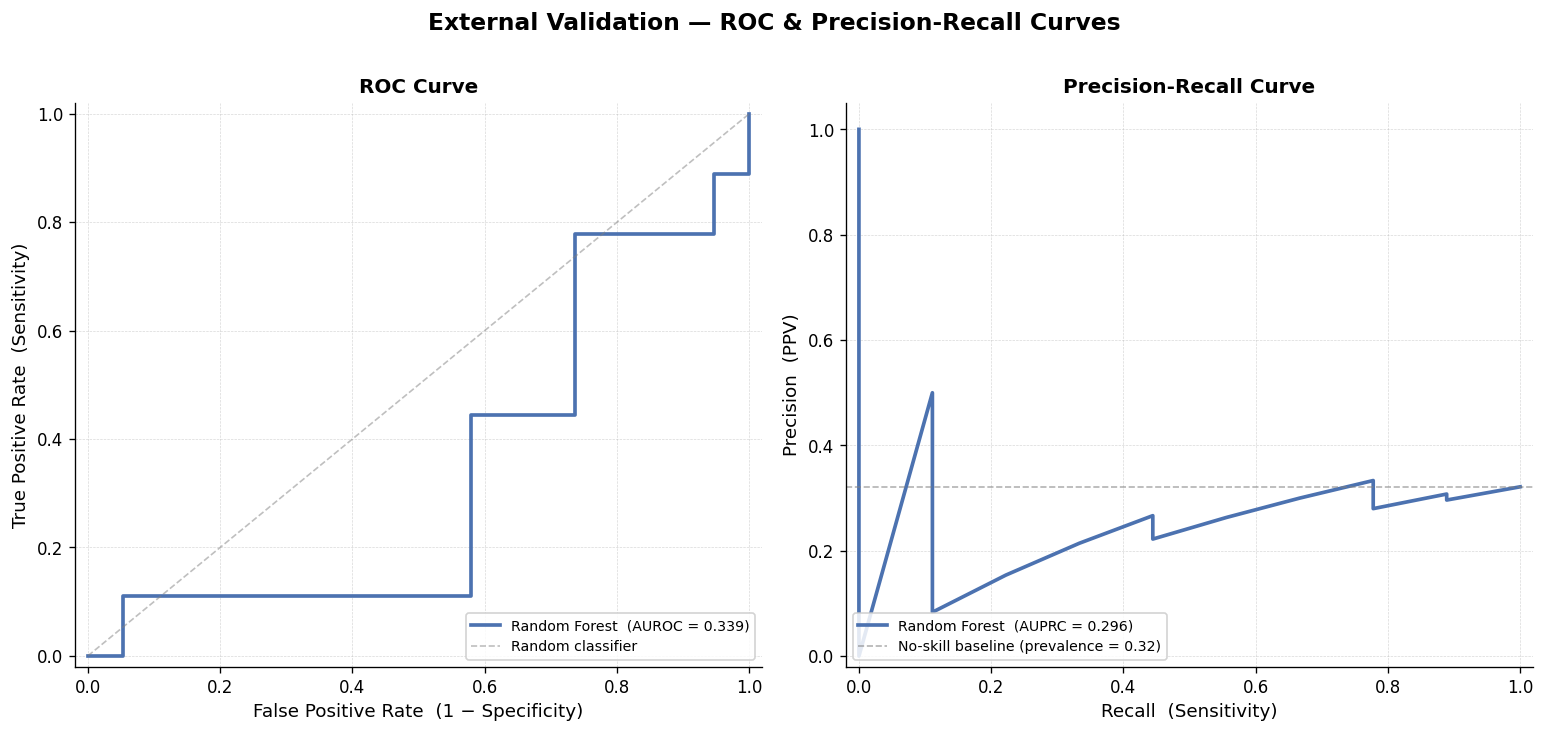

In [40]:
plot_external_validation_curves( y_true = y_val, y_prob = y_prob, model_name = "Random Forest" )

### F2. External Validation Confusion Matrix

##### The confusion matrix shows that the model correctly identified 1 of 9 responders and 17 of 19 non-responders, while misclassifying 8 responders and 2 non-responders. These results are consistent with the observed sensitivity (11.1%) and specificity (89.5%), indicating model performs better at identifying non-responders than responders.

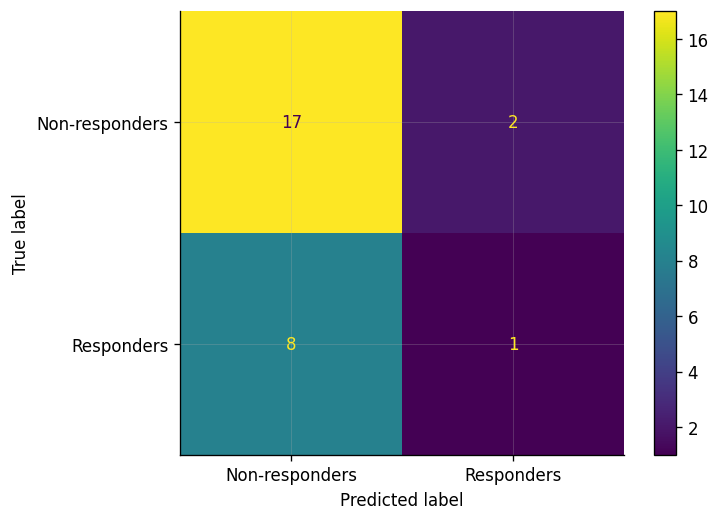

In [41]:
cm = confusion_matrix(y_val, y_val_pred)
class_names = ["Non-responders", "Responders"] 
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot()

### F3. Predicted Probability Distribution by True Class

##### The following violin plot shows the distribution of predicted probabilities for responders and non-responders in the external validation cohort. Although responders generally receive higher predicted probabilities than non-responders, considerable overlap is observed between the two distributions. This indicates that the Random Forest model does not clearly separate the two classes based on predicted probabilities, contributing to difficulty in reliably identifying responders.

(<Figure size 840x600 with 1 Axes>,
 <Axes: title={'center': 'Predicted Probabilities by true class'}, ylabel='Predicted Probability'>)

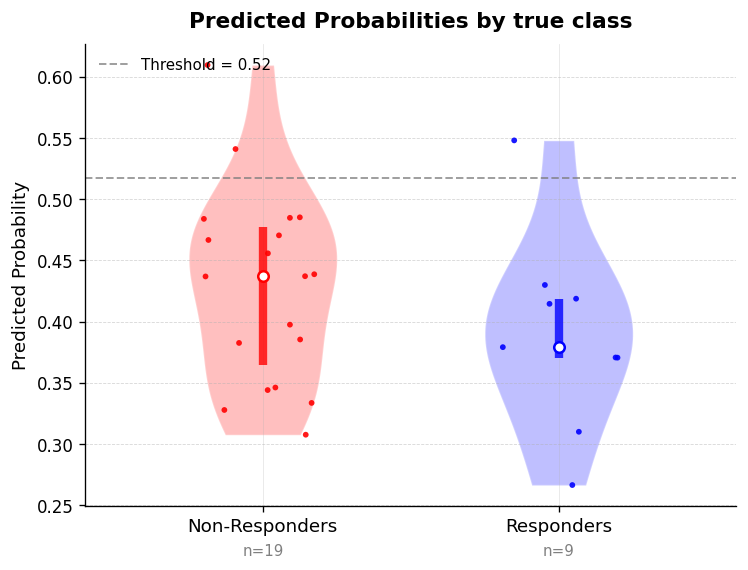

In [42]:
violin_plot_predictions(y_val, y_prob, [ "Non-Responders", "Responders"], colors = ["red", "blue"],point_alpha= 0.9, jitter=0.2, title= "Predicted Probabilities by true class", threshold=threshold_sel["threshold"])

### F4. Random Forest Model Feature Importance

#### The following figure shows the feature importance of the final Random Forest model used for external validation. Cell_Cycle, FAO/AMPK and Stroma show the highest importance, followed by Myeloid_inflammation, Complement_Cascade and T_effector. In contrast, the mutation features PBRM1, SETD2, and BAP1 show relatively low importance. 

(<Figure size 1080x655.2 with 1 Axes>,
 <Axes: title={'center': 'Random Forest Feature Importance'}, xlabel='Feature Importance'>)

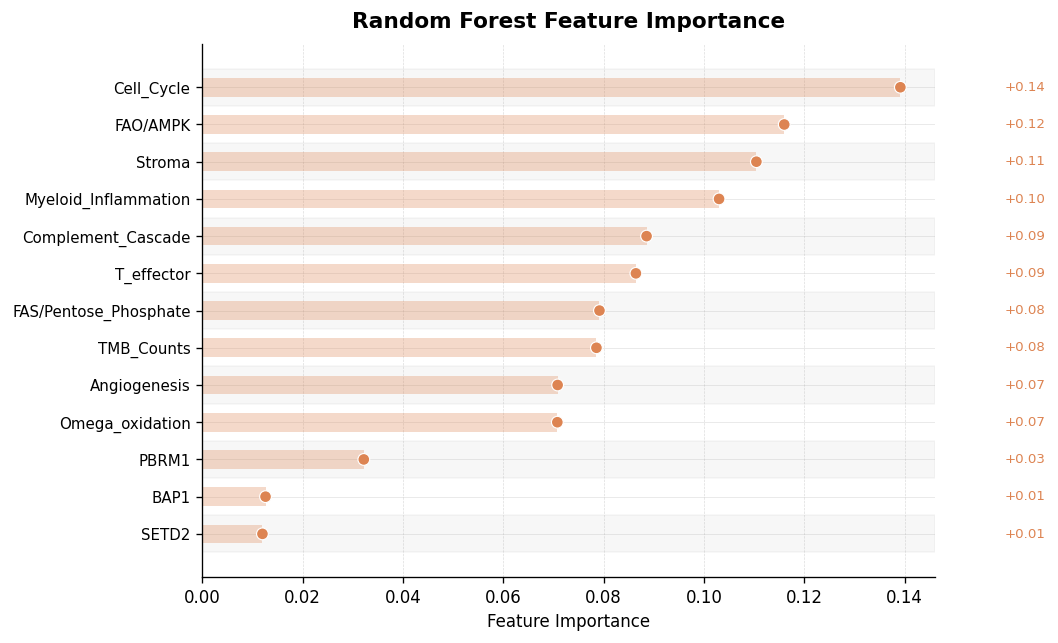

In [43]:
forest_plot_coefficients(feature_names,coefficients, mode = "coefficient", title = "Random Forest Feature Importance", xlabel="Feature Importance" )

## Part G. Bootstrap Analysis

In [44]:
observed_metrics = calculate_binary_metrics(
    y_val,
    y_prob,
    threshold=threshold_sel["threshold"]
)

print(observed_metrics)

{'AUROC': 0.33918128654970764, 'AUPRC': 0.2956011824432877, 'Sensitivity': np.float64(0.1111111111111111), 'Specificity': np.float64(0.8947368421052632), 'F1': 0.16666666666666666}


In [45]:
bootstrap_df, ci_df, skipped = bootstrap_external_metrics(
    y_true=y_val,
    y_prob=y_prob,
    threshold=threshold_sel["threshold"],
    n_bootstraps=5000,
    confidence_level=0.95,
    random_state=42
)

print(ci_df)
print("Skipped bootstrap samples:", skipped)

        metric  bootstrap_mean  bootstrap_median  ci_lower  ci_upper  \
0        AUROC        0.338807          0.333333  0.122449  0.585034   
1        AUPRC        0.336666          0.331854  0.146537  0.572482   
2  Sensitivity        0.112019          0.100000  0.000000  0.375000   
3  Specificity        0.893873          0.900000  0.736842  1.000000   
4           F1        0.155798          0.153846  0.000000  0.461538   

   valid_bootstraps  
0              5000  
1              5000  
2              5000  
3              5000  
4              5000  
Skipped bootstrap samples: 0


In [46]:
report_df = pd.DataFrame({
    "metric": observed_metrics.keys(),
    "estimate": observed_metrics.values()
})

report_df = report_df.merge(
    ci_df[
        [
            "metric",
            "ci_lower",
            "ci_upper",
            "valid_bootstraps"
        ]
    ],
    on="metric",
    how="left"
)

print(report_df)

        metric  estimate  ci_lower  ci_upper  valid_bootstraps
0        AUROC  0.339181  0.122449  0.585034              5000
1        AUPRC  0.295601  0.146537  0.572482              5000
2  Sensitivity  0.111111  0.000000  0.375000              5000
3  Specificity  0.894737  0.736842  1.000000              5000
4           F1  0.166667  0.000000  0.461538              5000


### Bootstrap 95% Confidence Intervals

##### The following figure presents the bootstrap 95% confidence intervals for Random Forest performance on the external validation cohort. The model achieved an AUROC of 0.339 and AUPRC of 0.296, indicating failure in discrimination and ranking performance. However, sensitivity was very low (0.111), while specificity was high (0.895), demonstrating that the model was substantially better at identifying non-responders than responders at the selected classification threshold. The low F1 score (0.167) further reflects the poor identification of the responder class. The relatively wide confidence intervals also highlight the uncertainty associated with the small external validation cohort.

(<Figure size 1080x600 with 1 Axes>,
 <Axes: title={'center': 'Bootstrap 95% CI — Model Performance'}, xlabel='Metric value'>)

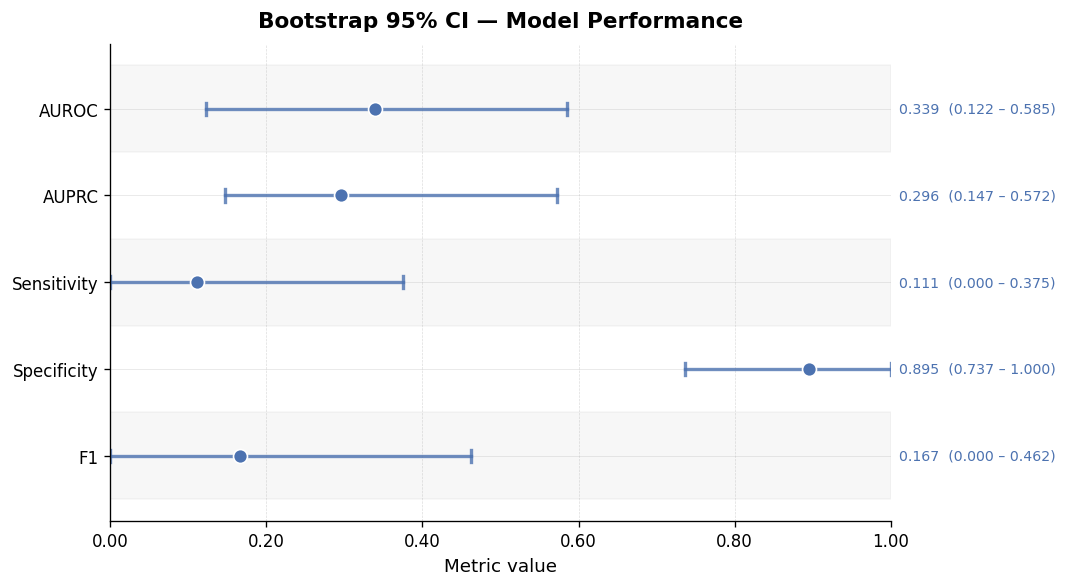

In [47]:
plot_bootstrap_ci_forest(report_df)

# Conclusion

#### 1. The Random Forest model was developed using repeated stratified cross-validation and hyperparameter tuning to explore non-linear relationships among molecular and clinical features for predicting immunotherapy response. 
#### 2. Cross-validation performance showed the model had difficulty identifying responders which is consistent with perfomance on external validation cohort. The model achieved an AUROC of 0.339, AUPRC OF 0.296, sensitivity of 0.111 and specificty of 0.895 demonstrating that the model was substantially better at identifying non-responders than responders. Class imbalance or RF overfitting on majority class could be the reason for its poor performance.

#### 3. Feature importance analysis identified Cell Cycle, FAO/AMPK and Stroma among the more influential predictors, while BAP1, SETD2, and PBRM1 showed relatively low importance. 
#### 4. Bootstrap analysis further demonstrated substantial uncertainty in responder-related metrics, particularly sensitivity and F1 score. Overall, although Random Forest showed poor ranking performance on the external cohort, its poor sensitivity and strong bias toward non-responder classification limit its usefulness as a balanced treatment-response classifier. These findings also suggest that the added non-linear complexity of Random Forest did not provide a clear advantage for this relatively small and imbalanced dataset.